In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [79]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "Iris.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "uciml/iris",
  file_path,
)

display(df.head())

Using Colab cache for faster access to the 'iris' dataset.


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [80]:
df = df.drop(columns=['Id'])
df.columns

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [81]:
#check for any null values
df.isnull().sum()

,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [82]:
# check for duplicated rows
df[df.duplicated()]

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
142,5.8,2.7,5.1,1.9,Iris-virginica


In [83]:
# Remove duplicate rows in-place
df = df.drop_duplicates()

In [84]:
X = df.drop(columns=['Species'])
y = df["Species"]

In [85]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler  = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2,random_state=42)

X_pca = pca.fit_transform(X_scaled)

In [86]:
pca.explained_variance_

array([2.92947202, 0.92751016])

In [87]:
pca.explained_variance_ratio_

array([0.72738591, 0.23030014])

In [88]:
pca.explained_variance_ratio_.sum()

np.float64(0.9576860515069875)

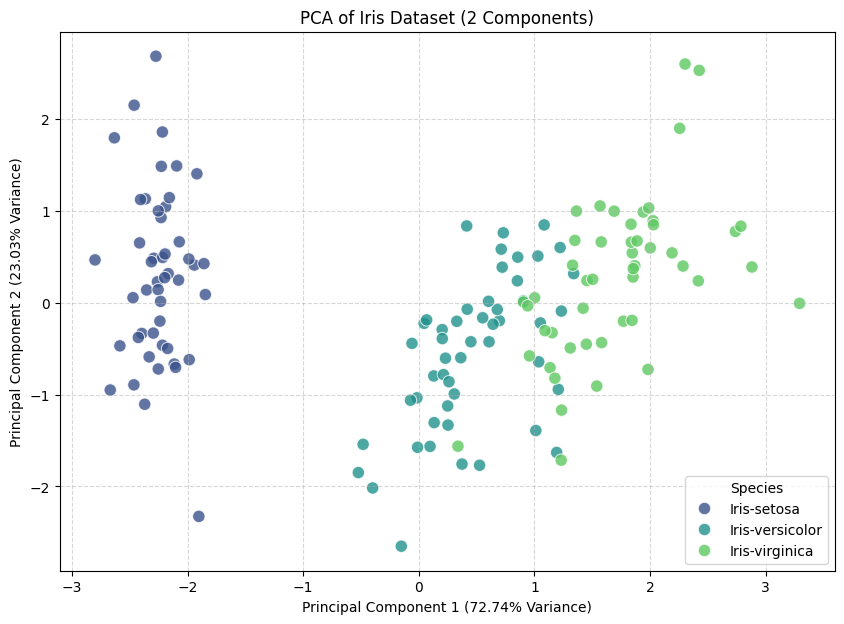

In [89]:
# Create a DataFrame with the PCA results and the target variable
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Species'] = y.values

# Plot the PCA results
plt.figure(figsize=(10, 7))
sns.scatterplot(x='PC1', y='PC2', hue='Species', data=pca_df, palette='viridis', s=80, alpha=0.8)
plt.title('PCA of Iris Dataset (2 Components)')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} Variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [90]:
X_pca_df = pd.DataFrame(data=X_pca, columns=['PC1','PC2'])
X_pca_df.head()

,PC1,PC2
0,-2.291654,0.486576
1,-2.115428,-0.666015
2,-2.396070,-0.332493
3,-2.332435,-0.587708
4,-2.415395,0.653930


In [91]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_pca_df,y, random_state=42, test_size=0.2)

In [92]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test= le.transform(y_test)

In [94]:
#Logistic Regression

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(random_state=42, penalty='elasticnet', solver='saga', l1_ratio=0.5, max_iter=5000)
lr.fit(X_train, y_train)

LogisticRegression(l1_ratio=0.5, max_iter=5000, penalty='elasticnet',
                   random_state=42, solver='saga')

In [95]:
y_pred = lr.predict(X_test)

In [96]:
#accuracy precision recall f1 , confusion matrix, roc-auc
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

In [97]:
accuracy_score(y_test,y_pred)

0.9

In [98]:
precision_score(y_test,y_pred,average="weighted")

0.9018939393939394

In [99]:
recall_score(y_test,y_pred,average="weighted")

0.9

In [100]:
f1_score(y_test,y_pred,average="weighted")

0.8994397759103641

In [101]:
confusion_matrix(y_test,y_pred)

array([[11,  0,  0],
       [ 0,  9,  1],
       [ 0,  2,  7]])

In [102]:
y_prob = lr.predict_proba(X_test)
roc_auc_score(y_test,y_prob,average="weighted",multi_class="ovr")

np.float64(0.9706349206349206)

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


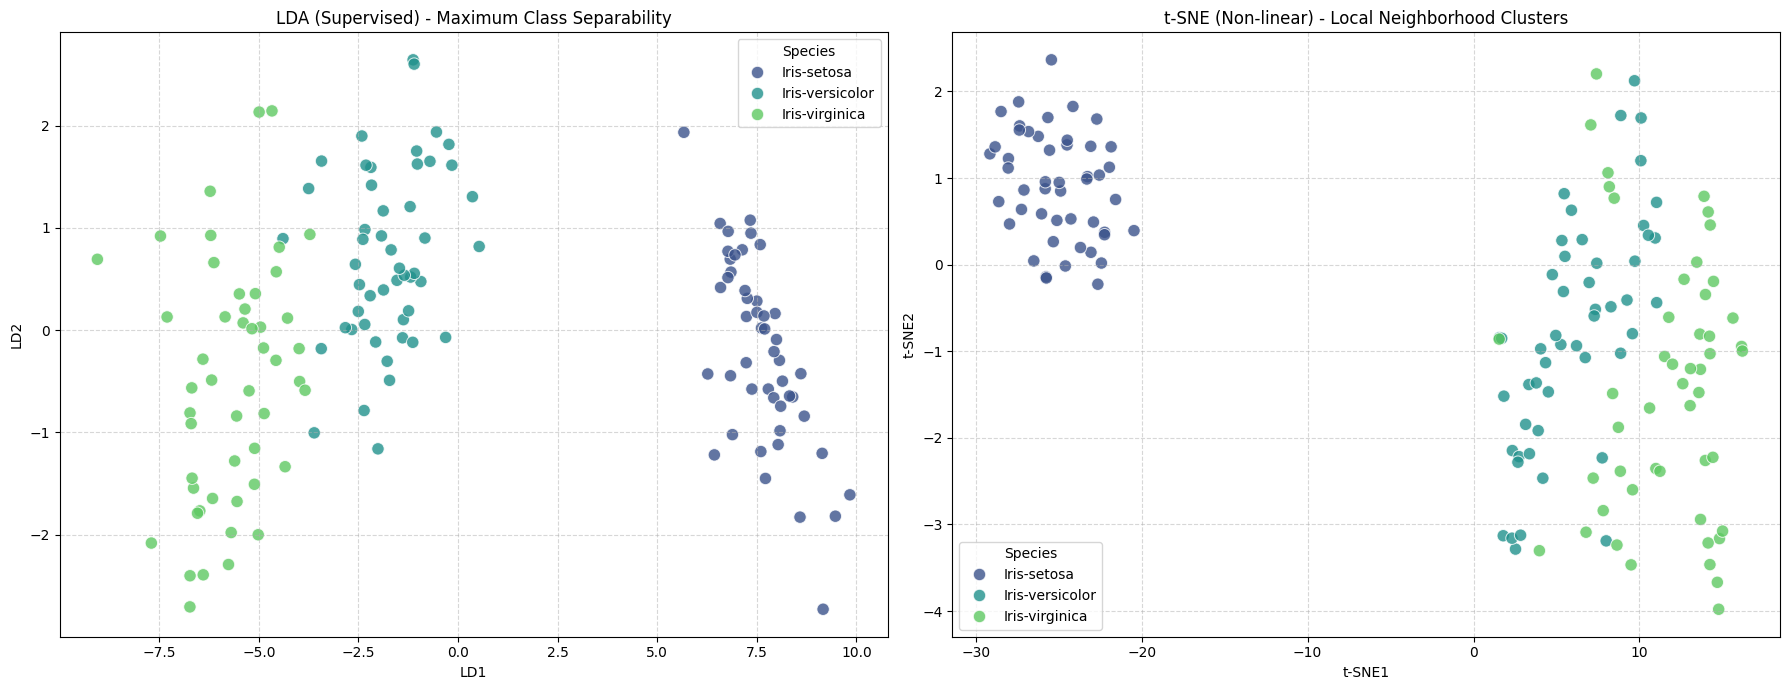

In [103]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE

# 1. Apply supervised Linear Discriminant Analysis (LDA)
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)
lda_df = pd.DataFrame(data=X_lda, columns=['LD1', 'LD2'])
lda_df['Species'] = y.values

# 2. Apply non-linear t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(data=X_tsne, columns=['t-SNE1', 't-SNE2'])
tsne_df['Species'] = y.values

# Plotting both side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# LDA Plot
sns.scatterplot(ax=axes[0], x='LD1', y='LD2', hue='Species', data=lda_df, palette='viridis', s=80, alpha=0.8)
axes[0].set_title('LDA (Supervised) - Maximum Class Separability')
axes[0].grid(True, linestyle='--', alpha=0.5)

# t-SNE Plot
sns.scatterplot(ax=axes[1], x='t-SNE1', y='t-SNE2', hue='Species', data=tsne_df, palette='viridis', s=80, alpha=0.8)
axes[1].set_title('t-SNE (Non-linear) - Local Neighborhood Clusters')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [104]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN (using 5 neighbors as a default starting point)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predict on the test set
y_pred_knn = knn.predict(X_test)
y_prob_knn = knn.predict_proba(X_test)

# Calculate and print metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, average='weighted')
knn_recall = recall_score(y_test, y_pred_knn, average='weighted')
knn_f1 = f1_score(y_test, y_pred_knn, average='weighted')
knn_roc_auc = roc_auc_score(y_test, y_prob_knn, average='weighted', multi_class='ovr')

print(f"--- KNN Evaluation Metrics ---")
print(f"Accuracy:  {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall:    {knn_recall:.4f}")
print(f"F1 Score:  {knn_f1:.4f}")
print(f"ROC-AUC:   {knn_roc_auc:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

--- KNN Evaluation Metrics ---
Accuracy:  0.9000
Precision: 0.9019
Recall:    0.9000
F1 Score:  0.8994
ROC-AUC:   0.9431

Confusion Matrix:
[[11  0  0]
 [ 0  9  1]
 [ 0  2  7]]


In [105]:
from sklearn.svm import SVC

# 1. Initialize and train the Linear SVM
svm_linear = SVC(kernel='linear', probability=True, random_state=42)
svm_linear.fit(X_train, y_train)

y_pred_linear = svm_linear.predict(X_test)
y_prob_linear = svm_linear.predict_proba(X_test)

# Calculate metrics for Linear SVM
acc_lin = accuracy_score(y_test, y_pred_linear)
prec_lin = precision_score(y_test, y_pred_linear, average='weighted')
rec_lin = recall_score(y_test, y_pred_linear, average='weighted')
f1_lin = f1_score(y_test, y_pred_linear, average='weighted')
roc_lin = roc_auc_score(y_test, y_prob_linear, average='weighted', multi_class='ovr')

# 2. Initialize and train the RBF SVM
svm_rbf = SVC(kernel='rbf', probability=True, random_state=42)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
y_prob_rbf = svm_rbf.predict_proba(X_test)

# Calculate metrics for RBF SVM
acc_rbf = accuracy_score(y_test, y_pred_rbf)
prec_rbf = precision_score(y_test, y_pred_rbf, average='weighted')
rec_rbf = recall_score(y_test, y_pred_rbf, average='weighted')
f1_rbf = f1_score(y_test, y_pred_rbf, average='weighted')
roc_rbf = roc_auc_score(y_test, y_prob_rbf, average='weighted', multi_class='ovr')

# Present comparison results
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Linear Kernel': [acc_lin, prec_lin, rec_lin, f1_lin, roc_lin],
    'RBF Kernel': [acc_rbf, prec_rbf, rec_rbf, f1_rbf, roc_rbf]
})

display(metrics_df.round(4))

# Print Confusion Matrices
print("\n--- Linear SVM Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_linear))
print("\n--- RBF SVM Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_rbf))

,Metric,Linear Kernel,RBF Kernel
0,Accuracy,0.8667,0.8667
1,Precision,0.8667,0.8667
2,Recall,0.8667,0.8667
3,F1-Score,0.8667,0.8667
4,ROC-AUC,0.9739,0.9805



--- Linear SVM Confusion Matrix ---
[[11  0  0]
 [ 0  8  2]
 [ 0  2  7]]

--- RBF SVM Confusion Matrix ---
[[11  0  0]
 [ 0  8  2]
 [ 0  2  7]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


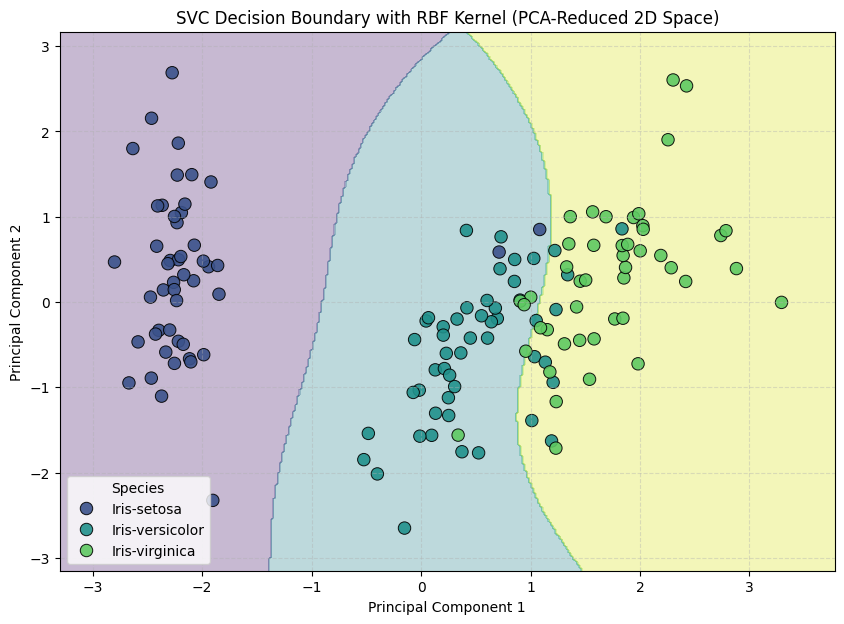

In [106]:
import numpy as np
import matplotlib.pyplot as plt

# Create a mesh grid to plot decision boundaries
x_min, x_max = X_pca_df['PC1'].min() - 0.5, X_pca_df['PC1'].max() + 0.5
y_min, y_max = X_pca_df['PC2'].min() - 0.5, X_pca_df['PC2'].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict class labels for each point on the grid using the trained RBF SVM
Z = svm_rbf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the contour and training/test data points
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Plot the actual data points
sns.scatterplot(x='PC1', y='PC2', hue=y, data=pca_df, palette='viridis', s=80, edgecolor='k', alpha=0.9)

plt.title('SVC Decision Boundary with RBF Kernel (PCA-Reduced 2D Space)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

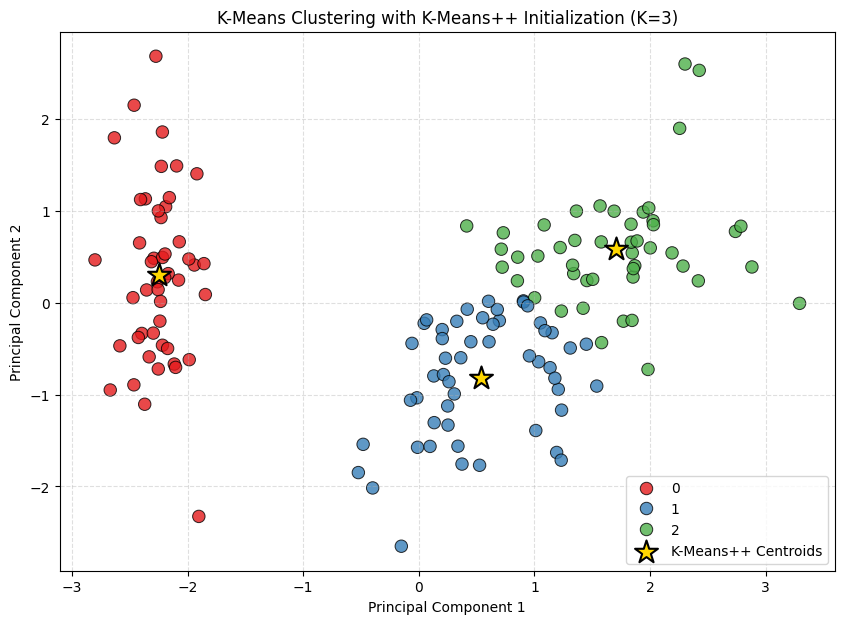

In [107]:
# Initialize KMeans explicitly using the 'k-means++' initialization strategy
from sklearn.cluster import KMeans

kmeans_pp = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)

# Fit on our 2D PCA-reduced dataset
kmeans_pp.fit(X_pca_df)

# Get cluster assignments and optimized centroids
pp_labels = kmeans_pp.labels_
pp_centroids = kmeans_pp.cluster_centers_

# Prepare DataFrame for visualization
kmeans_pp_df = X_pca_df.copy()
kmeans_pp_df['Cluster'] = pp_labels

# Plot the newly optimized clusters and centroids
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PC1', y='PC2', hue='Cluster', data=kmeans_pp_df,
    palette='Set1', s=80, alpha=0.8, edgecolor='k'
)

# Plot the final centroids
plt.scatter(
    pp_centroids[:, 0], pp_centroids[:, 1],
    color='gold', marker='*', s=300, label='K-Means++ Centroids', edgecolor='black', linewidth=1.5
)

plt.title('K-Means Clustering with K-Means++ Initialization (K=3)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

In [108]:
from scipy.stats import mode

# Encode the full true labels to integers
y_true_encoded = le.transform(y)

# Map each K-Means cluster label to the most frequent true class label within that cluster
mapped_cluster_labels = np.zeros_like(pp_labels)
for i in range(3):
    mask = (pp_labels == i)
    if np.sum(mask) > 0:
        majority_class = mode(y_true_encoded[mask], keepdims=True).mode[0]
        mapped_cluster_labels[mask] = majority_class

# Compute and display the classification accuracy
accuracy = accuracy_score(y_true_encoded, mapped_cluster_labels)
print(f"Unsupervised Classification Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Unsupervised Classification Accuracy: 0.8367 (83.67%)


In [109]:
import pandas as pd

# Compile results into a summary DataFrame
summary_data = {
    "Model": [
        "Logistic Regression (ElasticNet)",
        "K-Nearest Neighbors (KNN)",
        "Support Vector Classifier (Linear Kernel)",
        "Support Vector Classifier (RBF Kernel)",
        "K-Means++ (Unsupervised mapped to Ground Truth)"
    ],
    "Type": [
        "Supervised",
        "Supervised",
        "Supervised",
        "Supervised",
        "Unsupervised"
    ],
    "Accuracy": [
        0.9000,
        0.9000,
        0.8667,
        0.8667,
        0.8367
    ]
}

summary_df = pd.DataFrame(summary_data)
summary_df["Accuracy (%)"] = summary_df["Accuracy"] * 100

display(summary_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True))

,Model,Type,Accuracy,Accuracy (%)
0,Logistic Regression (ElasticNet),Supervised,0.9000,90.00
1,K-Nearest Neighbors (KNN),Supervised,0.9000,90.00
2,Support Vector Classifier (Linear Kernel),Supervised,0.8667,86.67
3,Support Vector Classifier (RBF Kernel),Supervised,0.8667,86.67
4,K-Means++ (Unsupervised mapped to Ground Truth),Unsupervised,0.8367,83.67


In [110]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict and evaluate
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average='weighted')
rf_recall = recall_score(y_test, y_pred_rf, average='weighted')
rf_f1 = f1_score(y_test, y_pred_rf, average='weighted')
rf_roc_auc = roc_auc_score(y_test, y_prob_rf, average='weighted', multi_class='ovr')

print("=== Random Forest Classifier Metrics ===")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

# Update the global comparison summary
new_row = {
    "Model": "Random Forest Classifier",
    "Type": "Supervised",
    "Accuracy": rf_accuracy,
    "Accuracy (%)": rf_accuracy * 100
}
summary_df = pd.concat([summary_df, pd.DataFrame([new_row])], ignore_index=True)

print("\nUpdated Summary Table:")
display(summary_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True))

=== Random Forest Classifier Metrics ===
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1 Score:  0.9333
ROC-AUC:   0.9571

Updated Summary Table:


,Model,Type,Accuracy,Accuracy (%)
0,Random Forest Classifier,Supervised,0.933333,93.333333
1,Logistic Regression (ElasticNet),Supervised,0.900000,90.000000
2,K-Nearest Neighbors (KNN),Supervised,0.900000,90.000000
3,Support Vector Classifier (Linear Kernel),Supervised,0.866700,86.670000
4,Support Vector Classifier (RBF Kernel),Supervised,0.866700,86.670000
5,K-Means++ (Unsupervised mapped to Ground Truth),Unsupervised,0.836700,83.670000


In [111]:
# We can conclude that Random forest algo performs well with an accuracy of 0.9333